# PathSnap Dataset Exploration

**Partitions:**
- Raw/train: 80 trips
- Raw/student-test: 10 trips
- Processed outputs: `processed/`



In [1]:
from pathlib import Path
import warnings
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('/home/neeraj-r-rugi/ML_Hackathon')
RAW_ROOT = ROOT / 'Student folder'
TRAIN_DIR = RAW_ROOT / 'train'
TEST_DIR = RAW_ROOT / 'student_test'
PROCESSED_DIR = ROOT / 'processed'
ASSET_DIR = ROOT / 'Dataset_explnation_assets'
ASSET_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)
print('Raw:', RAW_ROOT)
print('Processed:', PROCESSED_DIR)
print('Assets:', ASSET_DIR)


Raw: /home/neeraj-r-rugi/ML_Hackathon/Student folder
Processed: /home/neeraj-r-rugi/ML_Hackathon/processed
Assets: /home/neeraj-r-rugi/ML_Hackathon/Dataset_explnation_assets


## 1. Raw-file discovery and parsing

Each file is read from the no-header, whitespace-separated format. The manifest verifies row counts and graph IDs for every trip.

In [2]:
def trip_ids(root):
    return sorted(p.name for p in root.iterdir() if p.is_dir() and p.name.isdigit())

def read_raw(path, kind):
    if kind == 'track':
        return pd.read_csv(path, sep=r'\s+', header=None,
                           names=['lon','lat','timestamp'])
    if kind == 'nodes':
        return pd.read_csv(path, sep=r'\s+', header=None,
                           names=['lon','lat'])
    if kind == 'arcs':
        return pd.read_csv(path, sep=r'\s+', header=None,
                           names=['from_node','to_node'], dtype='int64')
    if kind == 'route':
        return pd.read_csv(path, sep=r'\s+', header=None,
                           names=['arc_id'], dtype='int64')
    raise ValueError(kind)

rows=[]
for partition, root in [('train',TRAIN_DIR), ('test',TEST_DIR)]:
    for trip_id in trip_ids(root):
        d=root/trip_id
        r={'partition':partition,'trip_id':trip_id}
        frames={}
        for kind in ('track','nodes','arcs','route'):
            p=d/f'{trip_id}.{kind}'
            r[f'{kind}_exists']=p.exists()
            if p.exists():
                frames[kind]=read_raw(p,kind)
                r[f'n_{kind}']=len(frames[kind])
            else:
                r[f'n_{kind}']=np.nan
        if 'track' in frames:
            t=frames['track']; dt=t.timestamp.diff()
            r.update(missing_track_values=int(t.isna().sum().sum()),
                      missing_lon=int(t.lon.isna().sum()),
                      missing_lat=int(t.lat.isna().sum()),
                      missing_timestamp=int(t.timestamp.isna().sum()),
                      non_increasing_time=int(dt.le(0).sum()),
                      gap_gt_1s=int(dt.gt(1).sum()),
                      median_dt=float(dt.median()),
                      min_lon=float(t.lon.min()),max_lon=float(t.lon.max()),
                      min_lat=float(t.lat.min()),max_lat=float(t.lat.max()),
                      start_time=float(t.timestamp.min()),end_time=float(t.timestamp.max()))
        if 'nodes' in frames and 'arcs' in frames:
            n=len(frames['nodes']); a=frames['arcs']
            bad=((a.from_node<0)|(a.from_node>=n)|(a.to_node<0)|(a.to_node>=n))
            r['invalid_arc_node_refs']=int(bad.sum())
        if 'route' in frames and 'arcs' in frames:
            bad=(~frames['route'].arc_id.between(0,len(frames['arcs'])-1))
            r['invalid_route_arc_refs']=int(bad.sum())
        rows.append(r)

raw_manifest=pd.DataFrame(rows)
raw_manifest.to_csv(ASSET_DIR/'raw_partition_manifest.csv',index=False)
print('Trips discovered:',len(raw_manifest))
display(raw_manifest.head())


Trips discovered: 90


,partition,trip_id,track_exists,n_track,nodes_exists,n_nodes,arcs_exists,n_arcs,route_exists,n_route,missing_track_values,missing_lon,missing_lat,missing_timestamp,non_increasing_time,gap_gt_1s,median_dt,min_lon,max_lon,min_lat,max_lat,start_time,end_time,invalid_arc_node_refs,invalid_route_arc_refs
0,train,00000001,True,1315,True,88809,True,165790,True,525,0,0,0,0,0,25,1.0,8.570524,8.647860,49.844053,50.211882,1.0,1358.000,0,0
1,train,00000002,True,7243,True,7936,True,16139,True,262,0,0,0,0,0,184,1.0,10.999961,11.050902,47.658344,47.695459,1.0,8934.156,0,0
2,train,00000003,True,821,True,9138,True,18028,True,79,0,0,0,0,0,3,1.0,37.154202,37.201595,55.977135,56.007585,1.0,824.000,0,0
3,train,00000004,True,1064,True,7350,True,15499,True,320,0,0,0,0,0,491,1.0,12.342280,12.459615,52.590308,52.718960,1.0,5218.000,0,0
4,train,00000005,True,1045,True,898,True,1579,True,105,0,0,0,0,0,0,1.0,35.485577,35.544315,49.357581,49.613085,1.0,1045.000,0,0


## 2. Partition summary and quality analysis

In [3]:
partition_summary=[]
for partition in ('train','test'):
    s=raw_manifest.query('partition == @partition')
    partition_summary.append({
        'partition':partition,'trips':len(s),
        'track_rows':int(s.n_track.sum()),'nodes_rows':int(s.n_nodes.sum()),
        'arcs_rows':int(s.n_arcs.sum()),'route_rows':int(s.n_route.sum()),
        'missing_track_values':int(s.missing_track_values.sum()),
        'gap_gt_1s_transitions':int(s.gap_gt_1s.sum()),
        'non_increasing_time':int(s.non_increasing_time.sum()),
        'invalid_arc_node_refs':int(s.invalid_arc_node_refs.fillna(0).sum()),
        'invalid_route_arc_refs':int(s.invalid_route_arc_refs.fillna(0).sum())})
partition_summary=pd.DataFrame(partition_summary)
partition_summary.loc[len(partition_summary)]={
    'partition':'total','trips':partition_summary.trips.sum(),
    'track_rows':partition_summary.track_rows.sum(),'nodes_rows':partition_summary.nodes_rows.sum(),
    'arcs_rows':partition_summary.arcs_rows.sum(),'route_rows':partition_summary.route_rows.sum(),
    'missing_track_values':partition_summary.missing_track_values.sum(),
    'gap_gt_1s_transitions':partition_summary.gap_gt_1s_transitions.sum(),
    'non_increasing_time':partition_summary.non_increasing_time.sum(),
    'invalid_arc_node_refs':partition_summary.invalid_arc_node_refs.sum(),
    'invalid_route_arc_refs':partition_summary.invalid_route_arc_refs.sum()}
partition_summary.to_csv(ASSET_DIR/'partition_summary.csv',index=False)
display(partition_summary)

row_ranges=(raw_manifest.groupby('partition')
            [['n_track','n_nodes','n_arcs','n_route']]
            .agg(['count','min','max','sum']))
row_ranges.to_csv(ASSET_DIR/'partition_row_ranges.csv')
display(row_ranges)


,partition,trips,track_rows,nodes_rows,arcs_rows,route_rows,missing_track_values,gap_gt_1s_transitions,non_increasing_time,invalid_arc_node_refs,invalid_route_arc_refs
0,train,80,208417,1933485,3876904,31336,0,7286,0,0,0
1,test,10,19160,90689,185041,3477,0,264,0,0,0
2,total,90,227577,2024174,4061945,34813,0,7550,0,0,0


n_track                     n_nodes                        n_arcs                        n_route                 
            count  min    max     sum   count   min     max      sum  count   min     max      sum   count min   max    sum
partition                                                                                                                  
test           10  262   3958   19160      10  1770   26635    90689     10  3577   56027   185041      10  95  1323   3477
train          80  361  19313  208417      80   299  155003  1933485     80   649  307392  3876904      80  59  2266  31336

## 3. Raw row-count distributions

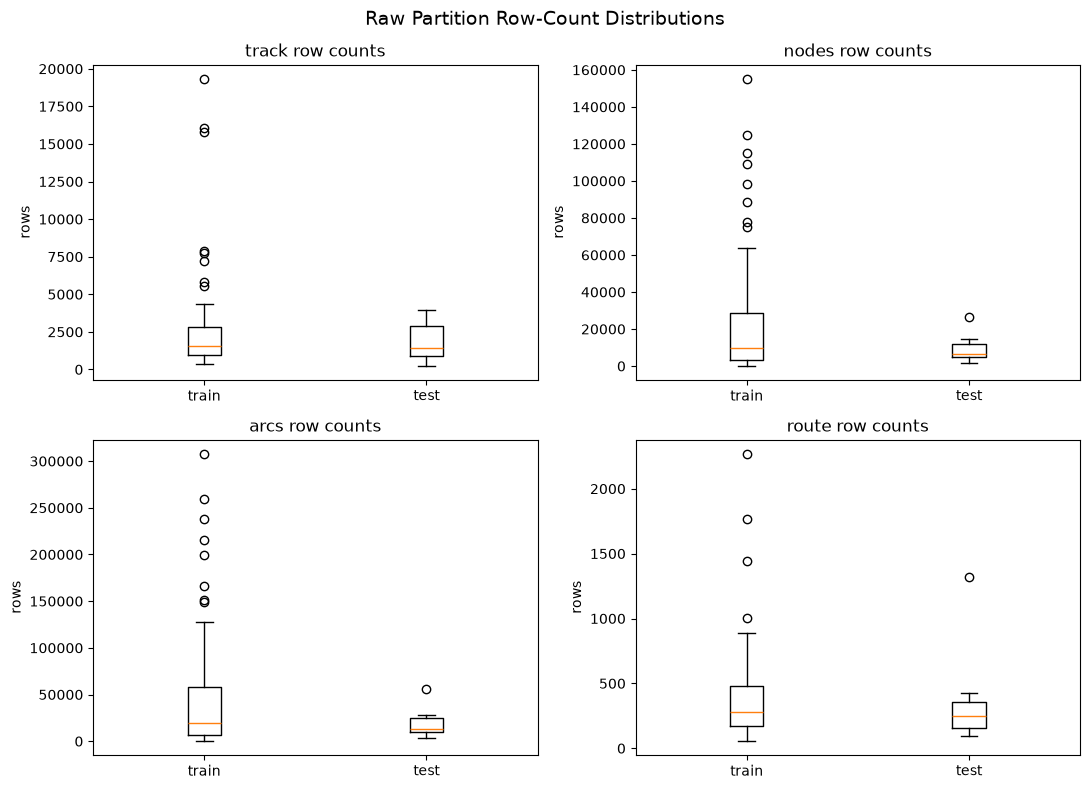

In [4]:
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,kind in zip(axes.ravel(),('track','nodes','arcs','route')):
    col=f'n_{kind}'
    ax.boxplot([raw_manifest.query("partition=='train'")[col].dropna(),
                raw_manifest.query("partition=='test'")[col].dropna()],
               tick_labels=['train','test'])
    ax.set_title(f'{kind} row counts'); ax.set_ylabel('rows')
fig.suptitle('Raw Partition Row-Count Distributions',fontsize=14)
fig.tight_layout(); fig.savefig(ASSET_DIR/'partition_row_count_boxplots.png',dpi=150)
plt.show()


## 4. GPS timestamp interval distribution across all training trips

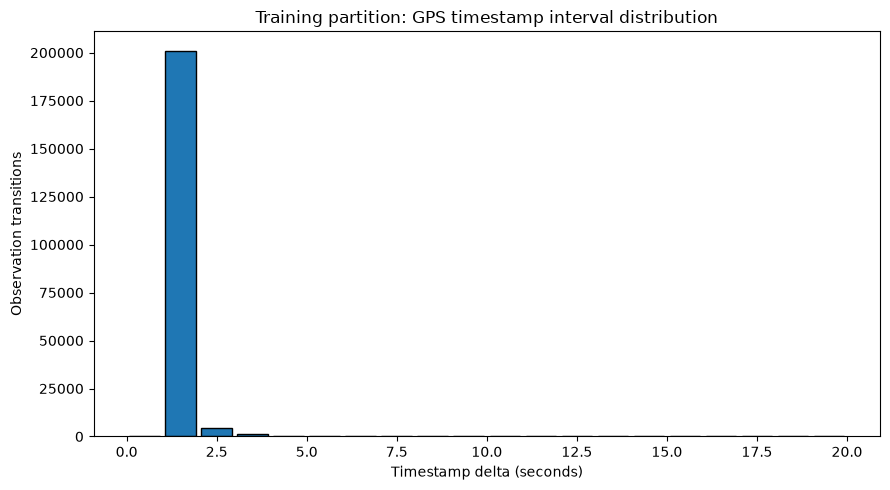

In [5]:
interval_values=[]
for trip_id in trip_ids(TRAIN_DIR):
    t=read_raw(TRAIN_DIR/trip_id/f'{trip_id}.track','track')
    interval_values.extend(t.timestamp.diff().dropna().clip(upper=20).tolist())
interval_series=pd.Series(interval_values,name='timestamp_delta_seconds')
interval_series.describe(percentiles=[.25,.5,.75,.95,.99]).to_frame().to_csv(ASSET_DIR/'training_timestamp_interval_summary.csv')

interval_series.plot(kind='hist',bins=range(0,21),rwidth=.85,figsize=(9,5),edgecolor='black')
plt.title('Training partition: GPS timestamp interval distribution')
plt.xlabel('Timestamp delta (seconds)'); plt.ylabel('Observation transitions')
plt.tight_layout(); plt.savefig(ASSET_DIR/'training_timing_intervals.png',dpi=150)
plt.show()


## 5. Representative trip: `00000001` (training partition)

This section plots raw GPS coordinates and overlays the trajectory on the trip's road network.


track 1315 nodes 88809 arcs 165790 route 525


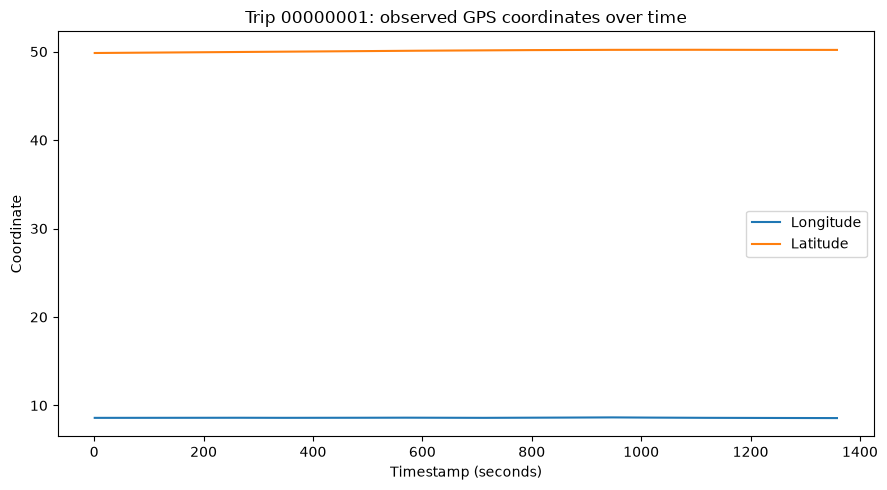

In [6]:
DEMO='00000001'; d=TRAIN_DIR/DEMO
t=read_raw(d/f'{DEMO}.track','track')
n=read_raw(d/f'{DEMO}.nodes','nodes')
a=read_raw(d/f'{DEMO}.arcs','arcs')
route=read_raw(d/f'{DEMO}.route','route')
print('track',len(t),'nodes',len(n),'arcs',len(a),'route',len(route))

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(t.timestamp,t.lon,label='Longitude'); ax.plot(t.timestamp,t.lat,label='Latitude')
ax.set_title('Trip 00000001: observed GPS coordinates over time')
ax.set_xlabel('Timestamp (seconds)'); ax.set_ylabel('Coordinate'); ax.legend()
fig.tight_layout(); fig.savefig(ASSET_DIR/'trip_00000001_coordinate_time.png',dpi=150)
plt.show()


## 6. Road-network visualisation

/tmp/ipykernel_135737/3318943857.py:13: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  ax.set_aspect('equal'); fig.tight_layout()
/tmp/ipykernel_135737/3318943857.py:14: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(ASSET_DIR/'trip_00000001_gps_over_network.png',dpi=150)
/home/neeraj-r-rugi/ML_Hackathon/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


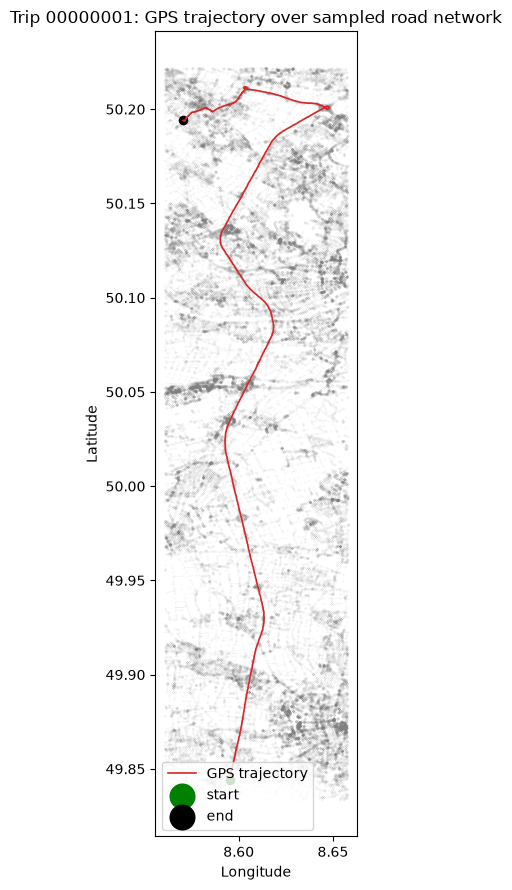

In [7]:
fig,ax=plt.subplots(figsize=(9,9))
step=20; sample=a.iloc[::step]
from_ids=sample.from_node.to_numpy(dtype=int); to_ids=sample.to_node.to_numpy(dtype=int)
ax.plot(np.vstack([n.lon.to_numpy()[from_ids],n.lon.to_numpy()[to_ids]]),
        np.vstack([n.lat.to_numpy()[from_ids],n.lat.to_numpy()[to_ids]]),
        color='0.55',linewidth=.15,alpha=.35)
ax.scatter(n.lon,n.lat,s=.02,c='gray',alpha=.25,rasterized=True)
ax.plot(t.lon,t.lat,c='tab:red',lw=1.2,label='GPS trajectory')
ax.scatter(t.lon.iloc[0],t.lat.iloc[0],c='green',s=35,label='start')
ax.scatter(t.lon.iloc[-1],t.lat.iloc[-1],c='black',s=35,label='end')
ax.set_title('Trip 00000001: GPS trajectory over sampled road network')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(markerscale=3)
ax.set_aspect('equal'); fig.tight_layout()
fig.savefig(ASSET_DIR/'trip_00000001_gps_over_network.png',dpi=150)
plt.show()


## 7. Interactive geographical map (Folium)

In [8]:
m=folium.Map(location=[t.lat.mean(),t.lon.mean()],zoom_start=14,tiles='OpenStreetMap')
folium.PolyLine(t[['lat','lon']].iloc[:300].values.tolist(),color='red',weight=4,opacity=.8,popup='GPS trajectory').add_to(m)
for arc in a.iloc[::30].itertuples():
    p1=n.iloc[arc.from_node]; p2=n.iloc[arc.to_node]
    folium.PolyLine([[p1.lat,p1.lon],[p2.lat,p2.lon]],color='gray',weight=.7,opacity=.35).add_to(m)
folium.Marker([t.lat.iloc[0],t.lon.iloc[0]],popup='Start',icon=folium.Icon(color='green')).add_to(m)
folium.Marker([t.lat.iloc[-1],t.lon.iloc[-1]],popup='End',icon=folium.Icon(color='black')).add_to(m)
map_path=ASSET_DIR/'trip_00000001_folium.html'; m.save(str(map_path))
print('Saved:',map_path)
m


Saved: /home/neeraj-r-rugi/ML_Hackathon/Dataset_explnation_assets/trip_00000001_folium.html


## 8. Processed-data and candidate coverage analysis

,split,trips,gps_rows,node_rows,arc_rows,candidate_rows,unmatched_gps,mean_unmatched
0,test,10,19160,90689,185041,356420,0,0.00
1,train,80,208417,1933485,3876904,3106041,8228,102.85


Processing failures: 0


,split,trip_id,gps_rows,node_rows,arc_rows,candidate_rows,unmatched_gps,status


Demo candidate rows: 28766 candidate GPS points: 1315 unmatched: 0


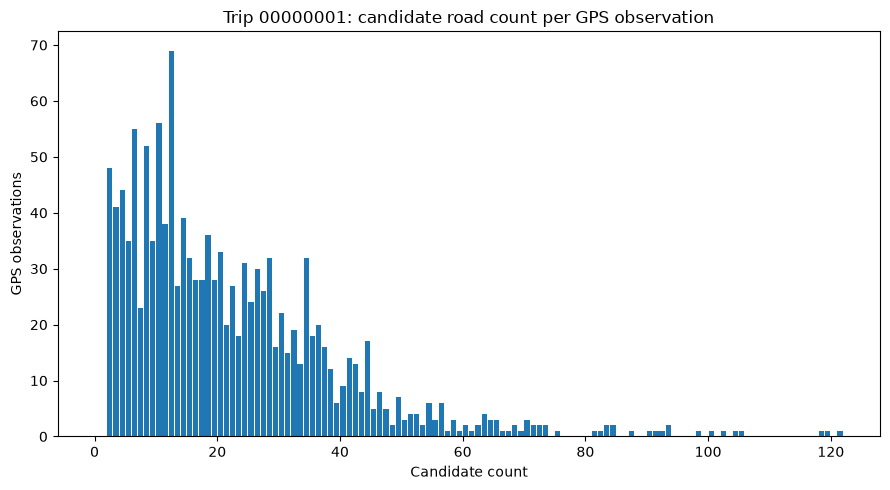

,distance_to_arc_m,projection_fraction,length_m,candidate_rank
count,28766.000000,28766.000000,28766.000000,28766.000000
mean,43.529720,0.500256,73.040646,17.371828
std,20.963683,0.459219,131.354937,16.817497
min,0.004126,0.000000,0.420624,0.000000
25%,27.014206,0.000000,12.989189,5.000000
50%,46.400720,0.500137,30.923244,13.000000
75%,61.670594,1.000000,77.394700,24.000000
max,74.992737,1.000000,1106.746485,120.000000


In [9]:
summary_path=PROCESSED_DIR/'processing_summary.csv'
if not summary_path.exists():
    raise FileNotFoundError('Run data_processing.ipynb first to generate processed/processing_summary.csv')
summary=pd.read_csv(summary_path)
processed_summary=(summary.groupby('split').agg(
    trips=('trip_id','count'),gps_rows=('gps_rows','sum'),node_rows=('node_rows','sum'),
    arc_rows=('arc_rows','sum'),candidate_rows=('candidate_rows','sum'),
    unmatched_gps=('unmatched_gps','sum'),mean_unmatched=('unmatched_gps','mean')).reset_index())
processed_summary.to_csv(ASSET_DIR/'processed_partition_summary.csv',index=False)
display(processed_summary)
print('Processing failures:',int((summary.status!='processed').sum()))
display(summary.query("status != 'processed'"))

candidate=pd.read_csv(PROCESSED_DIR/'train'/DEMO/'candidate_features.csv')
trackf=pd.read_csv(PROCESSED_DIR/'train'/DEMO/'track_features.csv')
counts=candidate[candidate.arc_id>=0].groupby('gps_index').size().reindex(range(len(trackf)),fill_value=0)
print('Demo candidate rows:',len(candidate),'candidate GPS points:',int((counts>0).sum()),'unmatched:',int((counts==0).sum()))

fig,ax=plt.subplots(figsize=(9,5))
ax.hist(counts,bins=range(0,int(counts.max())+2),rwidth=.85)
ax.set_title('Trip 00000001: candidate road count per GPS observation')
ax.set_xlabel('Candidate count'); ax.set_ylabel('GPS observations')
fig.tight_layout(); fig.savefig(ASSET_DIR/'trip_00000001_candidate_count_histogram.png',dpi=150)
plt.show()

cols=['distance_to_arc_m','projection_fraction','length_m','candidate_rank']
available=[c for c in cols if c in candidate.columns]
candidate[available].describe().to_csv(ASSET_DIR/'trip_00000001_candidate_feature_summary.csv')
display(candidate[available].describe())


## 9. Route-length and GPS-to-route-ratio analysis